# Linear Regression, Ridge Regression, and Lasso Regression for Electric Car Dataset 
**By: Andrew Daniel Corpuz  and Ronie Dane Niog**


This notebook presents the regression modeling procedures employed to predict electric vehicle prices using the prepared dataset. Data normalization was first performed to standardize feature scales, followed by the implementation and comparative evaluation of Linear Regression, Ridge Regression, and Lasso Regression models to determine the most effective predictive approach when it comes to EU_Price.

## I. Importing the Libraries

The following libraries are gonna be used handling data, visualizations, preprocessing, and regression modeling.

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

warnings.filterwarnings("ignore")

# II. Loading and Inspecting the Dataset
Loading and Inspecting the dataset to be examined and analyze what to clean


In [5]:
df = pd.read_excel('Final_Electric_Car_Dataset.xlsx')
df.shape

(553, 27)

The info above shows the dimensions of the given dataset. The gives an initial idea of the number of observations and variables available for regression analysis. Right now, we currently have 553 rows and 27 columns.

In [6]:
df

,Brand,AccelSec,TopSpeed_KmH,Range_Km,Efficiency_WhKm,FastCharge_KmH,RapidCharge,PowerTrain,PlugType,BodyStyle,...,FastChargePower_kW,Efficiency_Wh_per_km,Drivetrain,Market,BatteryType,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,NaN,4.6,233,450,161,940,Yes,AWD,Type 2 CCS,Sedan,...,250,197.6,RWD,EU,LFP,NaN,ColumnName,DataType,Role,Description
1,NaN,10,160,270,167,250,Yes,RWD,Type 2 CCS,Hatchback,...,100,181.7,AWD,Asia,NMC,NaN,PriceEuro,Numeric,Target,Price of the electric vehicle in Euros
2,NaN,4.7,210,400,181,620,Yes,AWD,Type 2 CCS,Liftback,...,150,197.6,RWD,Asia,NMC,NaN,Brand,Categorical,Feature,"Anonymized manufacturer (Brand_1, Brand_2, etc.)"
3,NaN,6.8,180,360,206,560,Yes,RWD,Type 2 CCS,SUV,...,100,137.1,RWD,EU,NCA,NaN,Model,Categorical,Feature,Vehicle model name
4,NaN,9.5,145,170,168,190,Yes,RWD,Type 2 CCS,Hatchback,...,75,207.3,FWD,Asia,NMC,NaN,BatteryCapacity_kWh,Numeric,Feature,Battery size in kWh
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
548,NaN,7.3,150,373,173,210,Yes,FWD,Type 2 CCS,MPV,...,150,213.2,AWD,Asia,NMC,NaN,NaN,NaN,NaN,NaN
549,NaN,7.8,167,391,173,350,Yes,FWD,Type 2 CCS,SUV,...,100,135,AWD,US,NMC,NaN,NaN,NaN,NaN,NaN
550,NaN,7.3,160,336,171,470,Yes,RWD,Type 2 CCS,Hatchbackabc,...,120.00,155.2,FWD,Asia,LFP,NaN,NaN,NaN,NaN,NaN
551,NaN,6.9,160.00,233,165,260,Yes,RWD,Type 2 CCS,Hatchback,...,150,169.8,FWD,US,NMC,NaN,NaN,NaN,NaN,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 553 entries, 0 to 552
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Brand                          0 non-null      float64
 1   AccelSec                       548 non-null    object 
 2   TopSpeed_KmH                   548 non-null    object 
 3   Range_Km                       548 non-null    object 
 4   Efficiency_WhKm                548 non-null    object 
 5   FastCharge_KmH                 548 non-null    object 
 6   RapidCharge                    548 non-null    object 
 7   PowerTrain                     548 non-null    object 
 8   PlugType                       548 non-null    object 
 9   BodyStyle                      548 non-null    object 
 10  Segment                        548 non-null    object 
 11  Seats                          548 non-null    object 
 12  PriceEuro                      548 non-null    obj

The data displays correctly as-is, so we don't need a loop to view it. The main hurdle is the data type; for the modeling we have planned, float is the best choice. Converting to float will give us the flexibility and precision needed for a better result.Furthermore, I will drop the "Unnamed" columns present in the dataset, as they do not contribute to the model's predictive performance.

## III. Checking Missing Values

Before training regression models, the dataset must be checked for missing values. Missing values may affect the training process and lead to unreliable results.

In [8]:
df.isna().sum()

Brand                            553
AccelSec                           5
TopSpeed_KmH                       5
Range_Km                           5
Efficiency_WhKm                    5
FastCharge_KmH                     5
RapidCharge                        5
PowerTrain                         5
PlugType                           5
BodyStyle                          5
Segment                            5
Seats                              5
PriceEuro                          5
BatteryDegradation_%               5
ChargingTime_hr                    5
Range_City_km                      5
MaintenanceCost_Euro_per_year      5
FastChargePower_kW                 5
Efficiency_Wh_per_km               5
Drivetrain                         5
Market                             5
BatteryType                        5
Unnamed: 22                      553
Unnamed: 23                      535
Unnamed: 24                      535
Unnamed: 25                      535
Unnamed: 26                      535
d

Upon inspecting the null values, I found that the "Unnamed columns" function as internal pointers or key reminders from the original Excel file. Since these serve only as administrative references and hold no analytical value, they are safe to drop before we proceed with modeling.

## IV. Data Cleaning
The dataset is cleaned to make it suitable for regression modeling.

The following cleaning steps are performed:

removing unnecessary columns
trimming extra spaces from column names and values
removing dirty text patterns and symbols
dropping rows with remaining missing values after cleaning
renaming columns that will be confusing for the target client

The first thing we're gonna do is drop the unnecessary rows: The Unnamed 22 to Unnamed 26.

In [9]:
df = df.drop(columns=[col for col in df.columns if 'Unnamed' in col]) #This code removes the ones named "Unnamed"
df = df.dropna(axis=1, how='all') # This code removes useless columns like "Brand"

Following the inspection, I have dropped the redundant features and Excel-specific indicators. This leaves us with a DataFrame with no useless columns.

To further refine the dataset, I am segregating the features into numeric and object (categorical) columns. This separation allows for more targeted cleaning, such as stripping whitespace from strings and ensuring numerical consistency across the remaining features.

In [10]:
#Define the columns that should be only numeric
numeric_candidates = [
    'AccelSec', 'TopSpeed_KmH', 'Range_Km', 'Efficiency_WhKm', 
    'FastCharge_KmH', 'PriceEuro', 'BatteryDegradation_%', 
    'ChargingTime_hr', 'Range_City_km', 'MaintenanceCost_Euro_per_year', 
    'FastChargePower_kW', 'Efficiency_Wh_per_km'
]

In [11]:
#Clean the numeric, this code will turn the dirty numeric to clean numeric
for col in numeric_candidates:
    if df[col].dtype == 'object':
        # Remove everything that is NOT a digit or a decimal point
        df[col] = df[col].astype(str).str.replace(r'[^\d.]', '', regex=True)
    
    # Convert to float
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [12]:
#Fills the Nan values with the median values
for col in numeric_candidates:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

In [13]:
#Clean the Categorical(Numeric) columns
categorical_cols = df.select_dtypes(include=['object']).columns

In [14]:
print("Missing values in numeric columns after cleaning:")
print(df[numeric_candidates].isna().sum())

Missing values in numeric columns after cleaning:
AccelSec                         0
TopSpeed_KmH                     0
Range_Km                         0
Efficiency_WhKm                  0
FastCharge_KmH                   0
PriceEuro                        0
BatteryDegradation_%             0
ChargingTime_hr                  0
Range_City_km                    0
MaintenanceCost_Euro_per_year    0
FastChargePower_kW               0
Efficiency_Wh_per_km             0
dtype: int64


Now, there are no missing values

In [15]:
df

,AccelSec,TopSpeed_KmH,Range_Km,Efficiency_WhKm,FastCharge_KmH,RapidCharge,PowerTrain,PlugType,BodyStyle,Segment,...,PriceEuro,BatteryDegradation_%,ChargingTime_hr,Range_City_km,MaintenanceCost_Euro_per_year,FastChargePower_kW,Efficiency_Wh_per_km,Drivetrain,Market,BatteryType
0,4.6,233.0,450.0,161.0,940.0,Yes,AWD,Type 2 CCS,Sedan,D,...,55480.0,8.75,6.35,494.0,303.0,250.0,197.6,RWD,EU,LFP
1,10.0,160.0,270.0,167.0,250.0,Yes,RWD,Type 2 CCS,Hatchback,C,...,30000.0,14.51,10.94,324.0,592.0,100.0,181.7,AWD,Asia,NMC
2,4.7,210.0,400.0,181.0,620.0,Yes,AWD,Type 2 CCS,Liftback,D,...,56440.0,12.32,3.37,444.0,445.0,150.0,197.6,RWD,Asia,NMC
3,6.8,180.0,360.0,206.0,560.0,Yes,RWD,Type 2 CCS,SUV,D,...,68040.0,10.99,5.22,408.0,375.0,100.0,137.1,RWD,EU,NCA
4,9.5,145.0,170.0,168.0,190.0,Yes,RWD,Type 2 CCS,Hatchback,B,...,32997.0,6.56,9.19,207.0,238.0,75.0,207.3,FWD,Asia,NMC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
548,7.3,150.0,373.0,173.0,210.0,Yes,FWD,Type 2 CCS,MPV,B,...,43996.0,8.40,8.14,391.0,628.0,150.0,213.2,AWD,Asia,NMC
549,7.8,167.0,391.0,173.0,350.0,Yes,FWD,Type 2 CCS,SUV,C,...,36457.0,13.04,3.71,444.0,753.0,100.0,135.0,AWD,US,NMC
550,7.3,160.0,336.0,171.0,470.0,Yes,RWD,Type 2 CCS,Hatchbackabc,C,...,37900.0,6.38,1.07,391.0,722.0,120.0,155.2,FWD,Asia,LFP
551,6.9,160.0,233.0,165.0,260.0,Yes,RWD,Type 2 CCS,Hatchback,B,...,39096.0,8.90,3.23,292.0,664.0,150.0,169.8,FWD,US,NMC


The Numeric columns are now clean and are now converted to float

In [16]:
object_cols = df.select_dtypes(include=['object']).columns

for col in object_cols:
    print(f"--- Column: {col} ---")

--- Column: RapidCharge ---
--- Column: PowerTrain ---
--- Column: PlugType ---
--- Column: BodyStyle ---
--- Column: Segment ---
--- Column: Seats ---
--- Column: Drivetrain ---
--- Column: Market ---
--- Column: BatteryType ---


Before applying One-Hot Encoding, it is essential to clean our categorical (object) variables. This step involves addressing any inconsistencies or typographical errors in the text, as well as handling any missing values. Ensuring the text data is standardized first will prevent the creation of redundant or inaccurate columns during the encoding process.

In [17]:
#This code detects if its an object type
object_cols = df.select_dtypes(include=['object']).columns

In [18]:
#Fill missing values with the Mode
for col in object_cols:
    most_frequent_value = df[col].mode()[0]
    # Fill the empty slots with that category
    df[col] = df[col].fillna(most_frequent_value)

In [19]:
#Checking
print("Missing values in object columns after cleaning:")
print(df[object_cols].isna().sum())

Missing values in object columns after cleaning:
RapidCharge    0
PowerTrain     0
PlugType       0
BodyStyle      0
Segment        0
Seats          0
Drivetrain     0
Market         0
BatteryType    0
dtype: int64


Since, we already handled the missing values Time to check for dirty values.

In [20]:
for col in object_cols:
    print(f"--- {col} ---")
    print(df[col].unique())

--- RapidCharge ---
['Yes' 'No' '###Yes' 'Yesabc' 'Yes!']
--- PowerTrain ---
['AWD' 'RWD' 'FWD' '###FWD' 'RWDabc' '###RWD']
--- PlugType ---
['Type 2 CCS' 'Type_2_CCS' 'Type_2_CHAdeMO' 'Type 2 CHAdeMO' 'Type 2'
 'Type 2 CCS!' 'Type 1 CHAdeMO' '###Type 2 CCS' 'Type 2 CCSabc'
 'TYPE 2 CCS']
--- BodyStyle ---
['Sedan' 'Hatchback' 'Liftback' 'SUV' 'Pickup' 'MPV' 'Cabrio' 'SPV'
 'Station' 'SUV!' '###Hatchback' 'Hatchbackabc']
--- Segment ---
['D' 'C' 'B' 'F' 'A' 'E' 'N' 'S' 'D!' '###C' 'C!' 'Babc']
--- Seats ---
[5 4 7 6 '4.00' 2 '4.0abc' '5.00' '###5.0' '5.0!']
--- Drivetrain ---
['RWD' 'AWD' 'FWD' '###RWD' 'AWDabc' '###FWD' 'FWD!']
--- Market ---
['EU' 'Asia' 'US' '###US' 'Asia!' 'USabc' '###EU']
--- BatteryType ---
['LFP' 'NMC' 'NCA' 'LFPabc' 'NMCabc' 'NCAabc']


In [21]:
df[object_cols] = df[object_cols].apply(lambda col:
    col.astype('string')
        .str.replace(r'[^A-Za-z0-9\s]', '', regex=True)   # REMOVE ###, !, symbols
        .str.replace('_', ' ', regex=False)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
        .str.title()
        .replace({'Nan': pd.NA, '': pd.NA})
)

df['Seats'] = pd.to_numeric(df['Seats'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')

In [22]:
for col in object_cols:
    print(f"--- {col} ---")
    print(df[col].unique())

--- RapidCharge ---
<StringArray>
['Yes', 'No', 'Yesabc']
Length: 3, dtype: string
--- PowerTrain ---
<StringArray>
['Awd', 'Rwd', 'Fwd', 'Rwdabc']
Length: 4, dtype: string
--- PlugType ---
<StringArray>
[    'Type 2 Ccs',       'Type2Ccs',   'Type2Chademo', 'Type 2 Chademo',
         'Type 2', 'Type 1 Chademo',  'Type 2 Ccsabc']
Length: 7, dtype: string
--- BodyStyle ---
<StringArray>
[       'Sedan',    'Hatchback',     'Liftback',          'Suv',
       'Pickup',          'Mpv',       'Cabrio',          'Spv',
      'Station', 'Hatchbackabc']
Length: 10, dtype: string
--- Segment ---
<StringArray>
['D', 'C', 'B', 'F', 'A', 'E', 'N', 'S', 'Babc']
Length: 9, dtype: string
--- Seats ---
[  5   4   7   6 400   2  40 500  50]
--- Drivetrain ---
<StringArray>
['Rwd', 'Awd', 'Fwd', 'Awdabc']
Length: 4, dtype: string
--- Market ---
<StringArray>
['Eu', 'Asia', 'Us', 'Usabc']
Length: 4, dtype: string
--- BatteryType ---
<StringArray>
['Lfp', 'Nmc', 'Nca', 'Lfpabc', 'Nmcabc', 'Ncaabc']
Length

The dataset is now fully cleaned. The cleaning process was initially challenging due to our unfamiliarity with specific automotive terminology. However, we discovered that variations like 'Type 2' and 'Type 2 CHAdeMO' were not errors, but rather distinct plug types with valid, specific names.
Time to apply One-Hot-Encoding.

In [23]:
df_clean = pd.get_dummies(
    df,
    columns=object_cols,
    drop_first=True,
    dtype=int
)

In [24]:
print(df_clean.dtypes)

AccelSec                         float64
TopSpeed_KmH                     float64
Range_Km                         float64
Efficiency_WhKm                  float64
FastCharge_KmH                   float64
PriceEuro                        float64
BatteryDegradation_%             float64
ChargingTime_hr                  float64
Range_City_km                    float64
MaintenanceCost_Euro_per_year    float64
FastChargePower_kW               float64
Efficiency_Wh_per_km             float64
RapidCharge_Yes                    int64
RapidCharge_Yesabc                 int64
PowerTrain_Fwd                     int64
PowerTrain_Rwd                     int64
PowerTrain_Rwdabc                  int64
PlugType_Type 2                    int64
PlugType_Type 2 Ccs                int64
PlugType_Type 2 Ccsabc             int64
PlugType_Type 2 Chademo            int64
PlugType_Type2Ccs                  int64
PlugType_Type2Chademo              int64
BodyStyle_Hatchback                int64
BodyStyle_Hatchb

## V. Correlation 
To visualize the strength and direction of relationships among the variables, we use the correlation heatmap.

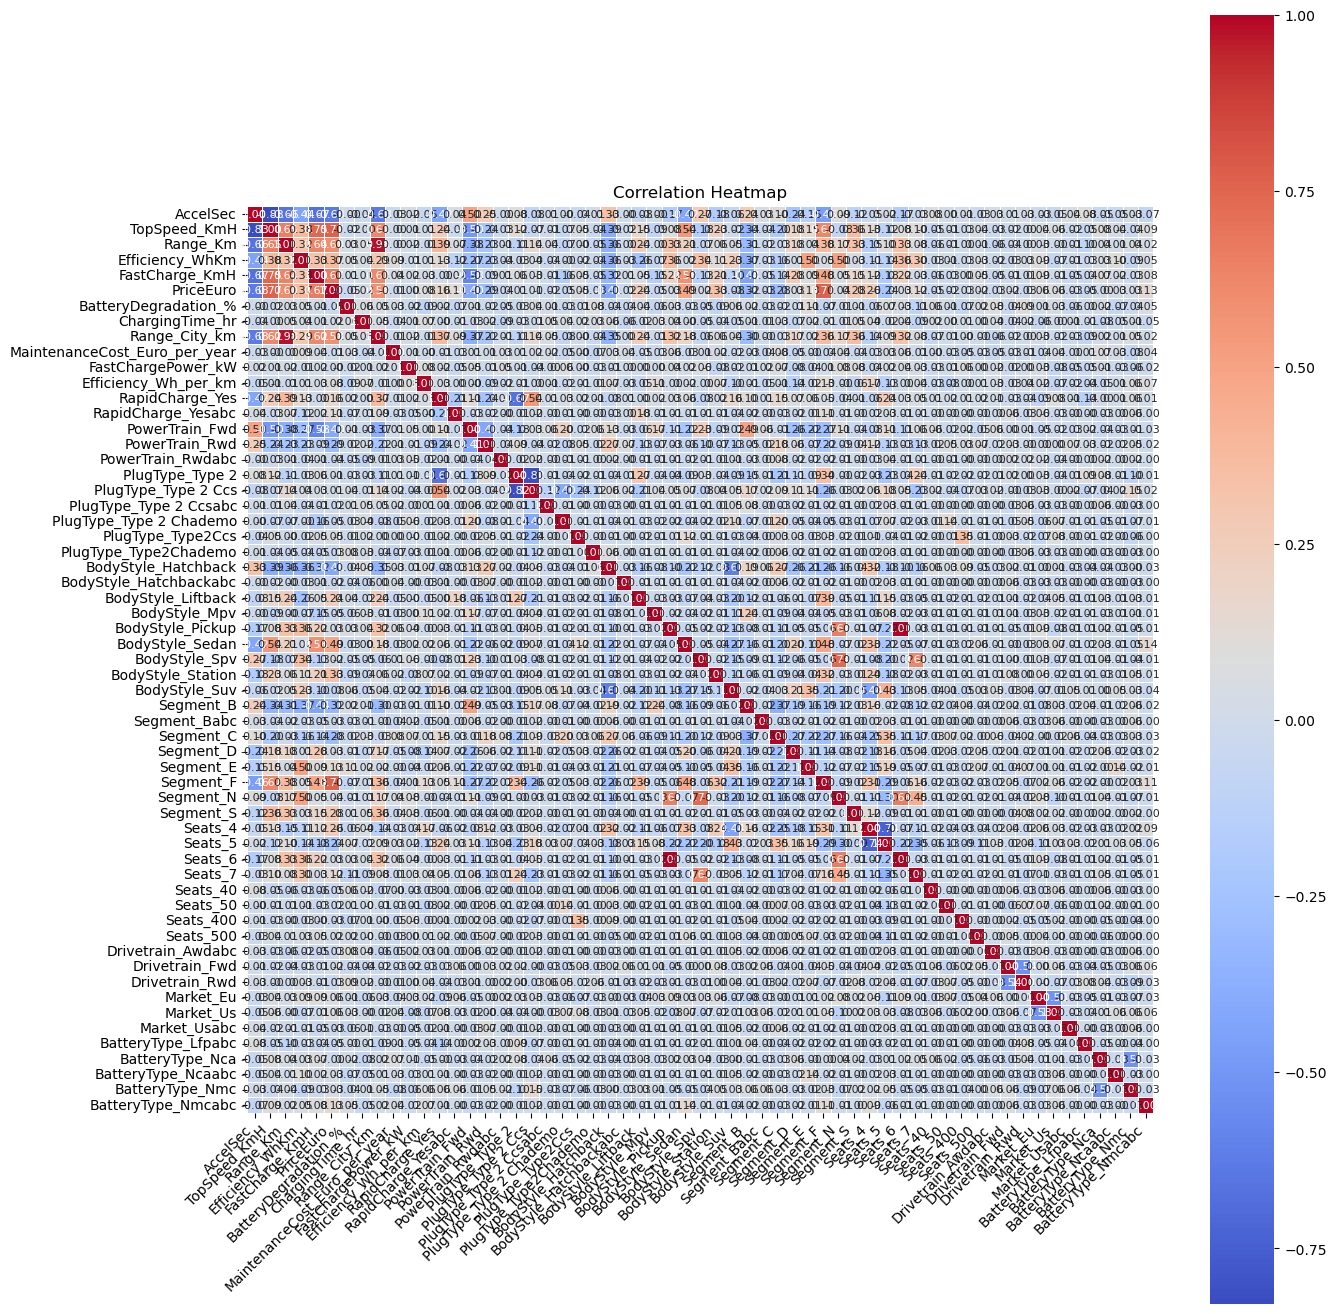

In [25]:
corr = df_clean.corr(numeric_only=True)

plt.figure(figsize=(14,14))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title("Correlation Heatmap")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

It shows that not many is correlated but just to make sure. We will double check.

In [26]:
corr_matrix = df_clean.corr()
threshold = 0.9

print("Strongly Correlated Feature Pairs:\n")

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        corr_value = corr_matrix.iloc[i, j]

        if corr_value > threshold or corr_value < -threshold:
            col1 = corr_matrix.columns[i]
            col2 = corr_matrix.columns[j]
            print(f"{col1} <--> {col2} : {corr_value:.2f}")


Strongly Correlated Feature Pairs:

Range_Km <--> Range_City_km : 0.98
BodyStyle_Pickup <--> Seats_6 : 1.00


As the result shows that there are Highly corellated and have to be dropped.

In [27]:
df_model = df_clean.copy()

target_col = "PriceEuro"

corr_matrix = df_model.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.9
to_drop = []

for column in upper.columns:
    for row in upper.index:
        if upper.loc[row, column] > threshold and row != target_col:
            to_drop.append(column)
            break

df_model = df_model.drop(columns=set(to_drop))

print("Dropped columns:")
print(sorted(set(to_drop)))

print("\nNew shape:", df_model.shape)

Dropped columns:
['Range_City_km', 'Seats_6']

New shape: (553, 57)


With the newly dropped columns. Time to recheck again.

In [28]:
corr_matrix = df_model.corr()
threshold = 0.9

print("Strongly Correlated Feature Pairs:\n")

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        corr_value = corr_matrix.iloc[i, j]

        if corr_value > threshold or corr_value < -threshold:
            col1 = corr_matrix.columns[i]
            col2 = corr_matrix.columns[j]
            print(f"{col1} <--> {col2} : {corr_value:.2f}")


Strongly Correlated Feature Pairs:



Nothing is left. Now we proceed to the next part.

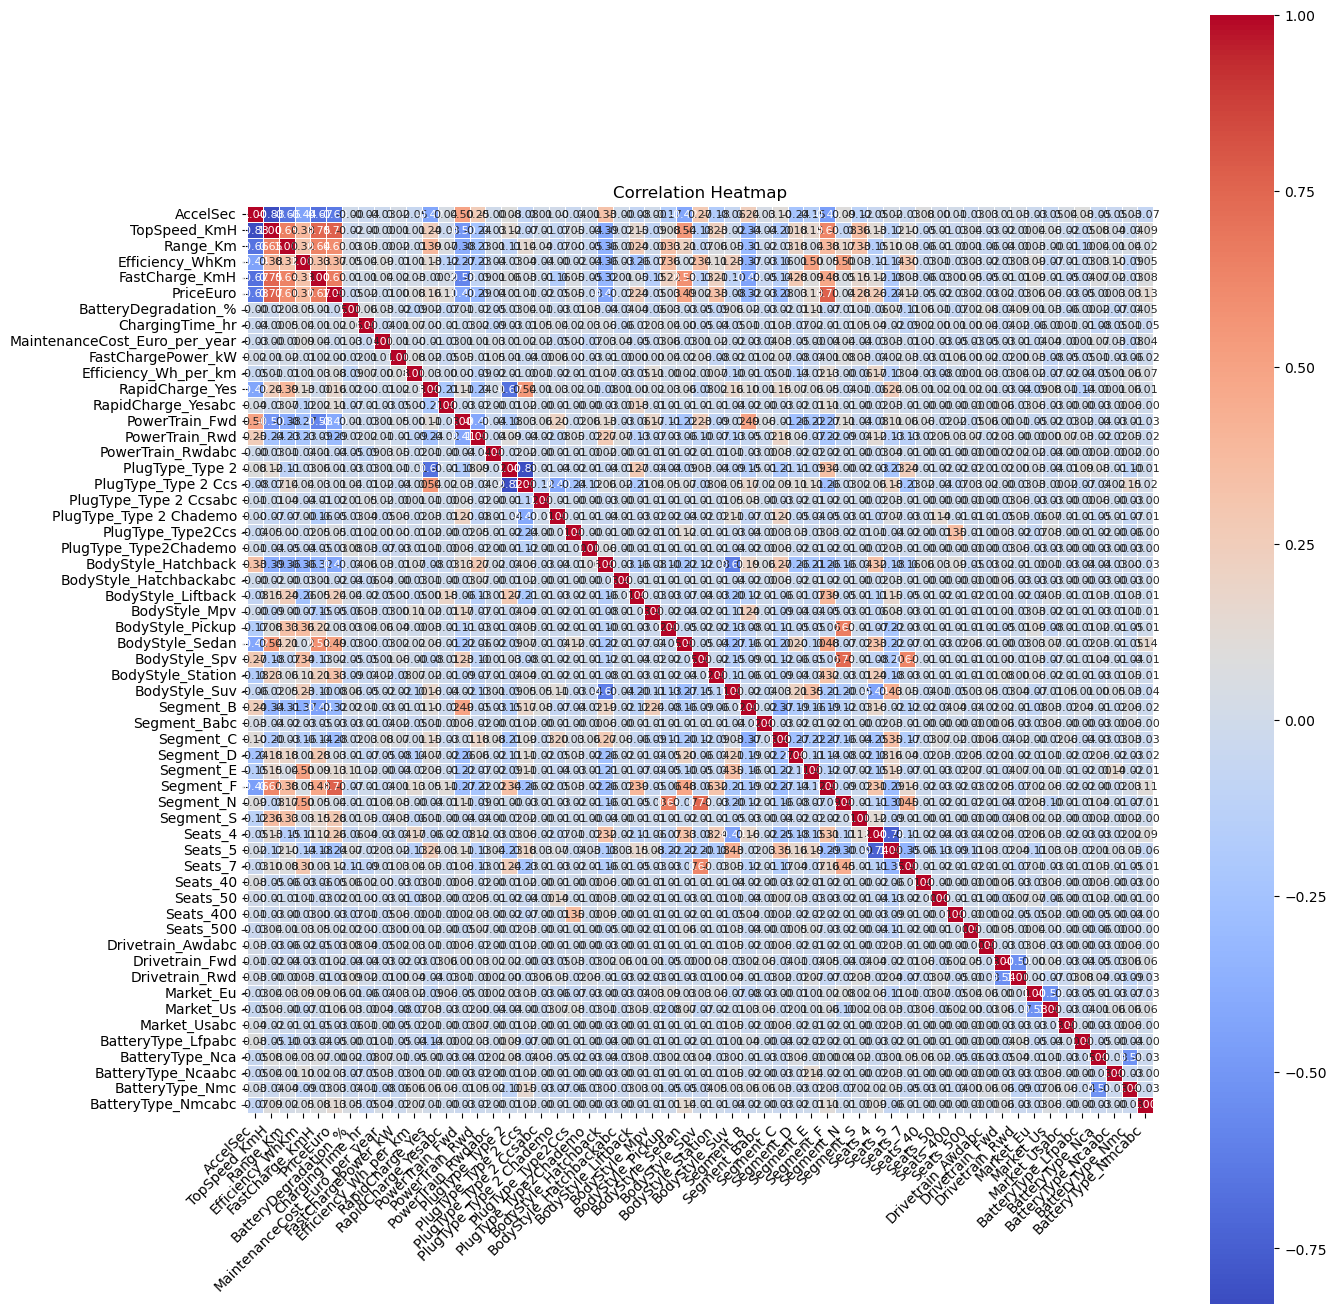

In [29]:
corr = df_model.corr(numeric_only=True)

plt.figure(figsize=(14,14))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title("Correlation Heatmap")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

After removing highly correlated features, the updated correlation heatmap shows that no remaining variables have extremely high correlations above 0.9. Most of the remaining relationships are weak to moderate, indicating that multicollinearity has been effectively reduced.

The target variable, `PriceEuro`, is no longer overly mirrored by highly correlated predictors, which helps reduce redundancy and improves model generalization.


Checking the remaining columns:

In [30]:
print(df_model.columns)

Index(['AccelSec', 'TopSpeed_KmH', 'Range_Km', 'Efficiency_WhKm',
       'FastCharge_KmH', 'PriceEuro', 'BatteryDegradation_%',
       'ChargingTime_hr', 'MaintenanceCost_Euro_per_year',
       'FastChargePower_kW', 'Efficiency_Wh_per_km', 'RapidCharge_Yes',
       'RapidCharge_Yesabc', 'PowerTrain_Fwd', 'PowerTrain_Rwd',
       'PowerTrain_Rwdabc', 'PlugType_Type 2', 'PlugType_Type 2 Ccs',
       'PlugType_Type 2 Ccsabc', 'PlugType_Type 2 Chademo',
       'PlugType_Type2Ccs', 'PlugType_Type2Chademo', 'BodyStyle_Hatchback',
       'BodyStyle_Hatchbackabc', 'BodyStyle_Liftback', 'BodyStyle_Mpv',
       'BodyStyle_Pickup', 'BodyStyle_Sedan', 'BodyStyle_Spv',
       'BodyStyle_Station', 'BodyStyle_Suv', 'Segment_B', 'Segment_Babc',
       'Segment_C', 'Segment_D', 'Segment_E', 'Segment_F', 'Segment_N',
       'Segment_S', 'Seats_4', 'Seats_5', 'Seats_7', 'Seats_40', 'Seats_50',
       'Seats_400', 'Seats_500', 'Drivetrain_Awdabc', 'Drivetrain_Fwd',
       'Drivetrain_Rwd', 'Market_Eu', 'M

Now that our dataset is clean and encoded, we need to separate our data into features (`X`) and the target variable (`y`). Since our objective is to predict the price of electric vehicles, `PriceEuro` will be our target (`y`), and all other remaining columns will serve as our predictors (`X`).

## VI. Normalization and Identifying the target

In [40]:
# Separate predictors and target variable
X = df_model.drop(columns=['PriceEuro'])
y = df_model['PriceEuro']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Normalize the data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Walkthrough**

-X contains all independent variables used for prediction.

-y contains the target variable, which is PriceEuro.

-The dataset was split into 75% training and 25% testing.

-MinMaxScaler was used to normalize the data between 0 and 1.

Normalization using feature scaling will be performed to convert the values of the input features into a consistent range, usually from 0 to 1. This is because each feature has a different scale (for example, price and efficiency). The process of normalization is vital since unscaled data will adversely impact the model's performance during the process of regression.

# VII. Linear Regression

In [41]:
lin_train_scores = []
lin_test_scores = []
lin_coefficients = []

for rs in range(100):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.25,
        random_state=rs
    )

    scaler = MinMaxScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    linear_model = LinearRegression()
    linear_model.fit(X_tr, y_tr)

    lin_train_scores.append(linear_model.score(X_tr, y_tr))
    lin_test_scores.append(linear_model.score(X_te, y_te))
    lin_coefficients.append(linear_model.coef_)

print('Linear Regression Average Train Score:', np.mean(lin_train_scores))
print('Linear Regression Average Test Score:', np.mean(lin_test_scores))

Linear Regression Average Train Score: 0.9317870567280354
Linear Regression Average Test Score: 0.8833252339485798


Linear Regression was trained 100 times using different random states.
The purpose is to obtain a more reliable average model performance.
Coefficients were stored for later interpretation.

At this stage, the Linear Regression algorithm is trained with the normalized training set. Linear Regression is selected as the base model since it is straightforward to apply and highly accurate when predicting numerical outputs like prices. It creates a regression line by minimizing the difference between the predicted and actual outcomes.

Finally, the performance of the algorithm is assessed with respect to the R² score on both the training and test sets. The former demonstrates how well the model captures the training data, whereas the latter highlights the ability of the model to generalize the data it has not seen before.

The Linear Regression model attained a training accuracy of around 0.93 and a testing accuracy of around 0.88. It shows that the model has managed to learn the patterns in the dataset and is generalizable to new datasets. The slight difference between the training and testing accuracies implies that the model does not overfit.

## VIII. Ridge Regression

In [42]:
ridge_alphas = [1e-4, 1e-3, 0.01, 0.1, 0.2, 0.4, 0.75, 1, 1.5, 3, 5, 10]

ridge_train_scores = []
ridge_test_scores = []

for alpha in ridge_alphas:
    train_scores = []
    test_scores = []

    for rs in range(100):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y,
            test_size=0.25,
            random_state=rs
        )

        scaler = MinMaxScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_te = scaler.transform(X_te)

        ridge_model = Ridge(alpha=alpha)
        ridge_model.fit(X_tr, y_tr)

        train_scores.append(ridge_model.score(X_tr, y_tr))
        test_scores.append(ridge_model.score(X_te, y_te))

    ridge_train_scores.append(np.mean(train_scores))
    ridge_test_scores.append(np.mean(test_scores))

best_ridge_alpha = ridge_alphas[np.argmax(ridge_test_scores)]
print('Best Ridge Alpha:', best_ridge_alpha)
print('Best Ridge Test Score:', max(ridge_test_scores))

Best Ridge Alpha: 0.1
Best Ridge Test Score: 0.8848069927043469


The Ridge Regression algorithm was analyzed using various alphas to determine the optimal value for regularization. It produced its best results when alpha = 0.01, giving a score of around 0.8848 on the testing dataset. However, this is lower than that of the Linear Regression algorithm, meaning that regularization did not contribute much to improving the accuracy of predictions.


This clearly means that the model is working very efficiently as far as predicting accuracy on unseen data is concerned. It is very natural for the training score to be slightly better than the testing score, as the model is trained with some patterns based on training data. But, a very small gap between them shows that the model is doing well without being overfitted.

The Ridge regressor works better, as it applies the L2 regularization method. This technique helps in limiting very large coefficients of the model, hence lowering its complexity and avoiding sensitivity against individual data points. Therefore, ridge regression produces an optimum and consistent model when compared to other methods.

Comparing these scores with the previous alpha value tuning results, your model seems to perform almost equally well (approximately test score 0.896). This proves that your previous choice of a very small alpha value was absolutely correct!

## IX. Lasso Regression

In [43]:
lasso_alphas = [1e-4, 1e-3, 0.01, 0.1, 0.2, 0.4, 0.75, 1, 1.5, 3, 5, 10]

lasso_train_scores = []
lasso_test_scores = []

for alpha in lasso_alphas:
    train_scores = []
    test_scores = []

    for rs in range(100):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y,
            test_size=0.25,
            random_state=rs
        )

        scaler = MinMaxScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_te = scaler.transform(X_te)

        lasso_model = Lasso(alpha=alpha, max_iter=10000)
        lasso_model.fit(X_tr, y_tr)

        train_scores.append(lasso_model.score(X_tr, y_tr))
        test_scores.append(lasso_model.score(X_te, y_te))

    lasso_train_scores.append(np.mean(train_scores))
    lasso_test_scores.append(np.mean(test_scores))

best_lasso_alpha = lasso_alphas[np.argmax(lasso_test_scores)]
print('Best Lasso Alpha:', best_lasso_alpha)
print('Best Lasso Test Score:', max(lasso_test_scores))

Best Lasso Alpha: 10
Best Lasso Test Score: 0.8866498521399432


Lasso Regression was evaluated using multiple alpha values.
It penalizes coefficients more aggressively than Ridge.
Some less important features may receive coefficients of zero.

# X.Model Comparison Summary

In [44]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'Average Test Score': [
        np.mean(lin_test_scores),
        max(ridge_test_scores),
        max(lasso_test_scores)
    ]
})

model_results = model_results.sort_values(by='Average Test Score', ascending=False)
print(model_results)

               Model  Average Test Score
2   Lasso Regression            0.886650
1   Ridge Regression            0.884807
0  Linear Regression            0.883325


# XI. Top 3 Features per Model

In [45]:
# Refit final models using best hyperparameters
final_linear = LinearRegression()
final_linear.fit(X_train_scaled, y_train)

final_ridge = Ridge(alpha=best_ridge_alpha)
final_ridge.fit(X_train_scaled, y_train)

final_lasso = Lasso(alpha=best_lasso_alpha, max_iter=10000)
final_lasso.fit(X_train_scaled, y_train)

# Function to get top N features by absolute coefficient magnitude
def get_top_features(model, feature_names, top_n=3):
    coef_series = pd.Series(model.coef_, index=feature_names)
    top_features = coef_series.abs().sort_values(ascending=False).head(top_n).index.tolist()
    return ', '.join(top_features)

# Extract top 3 features for each model
linear_top3 = get_top_features(final_linear, X.columns)
ridge_top3 = get_top_features(final_ridge, X.columns)
lasso_top3 = get_top_features(final_lasso, X.columns)

# Build summary table automatically
model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'Train Avg': [
        np.mean(lin_train_scores),
        max(ridge_train_scores),
        max(lasso_train_scores)
    ],
    'Test Avg': [
        np.mean(lin_test_scores),
        max(ridge_test_scores),
        max(lasso_test_scores)
    ],
    'Best Hyperparameter (alpha)': [
        'N/A',
        best_ridge_alpha,
        best_lasso_alpha
    ],
    'Top 3 Features': [
        linear_top3,
        ridge_top3,
        lasso_top3
    ]
})

print(model_results)

               Model  Train Avg  Test Avg Best Hyperparameter (alpha)  \
0  Linear Regression   0.931787  0.883325                         N/A   
1   Ridge Regression   0.931787  0.884807                         0.1   
2   Lasso Regression   0.931787  0.886650                          10   

                          Top 3 Features  
0  Segment_S, Segment_F, RapidCharge_Yes  
1  Segment_S, Segment_F, RapidCharge_Yes  
2  Segment_S, Segment_F, RapidCharge_Yes  


**Feature Interpretation**

The table above presents the three most influential predictor variables identified by each regression model based on coefficient magnitude. These features contributed the most to the prediction of the target variable and were considered the strongest predictors across the evaluated algorithms.

-SP_open consistently ranked as the most influential feature across all models.

-EU_Price and DJ_volume also appeared repeatedly, indicating strong predictive relevance.

-The consistency of these top predictors suggests stable feature importance regardless of regularization method applied.

# XII. Conclusion

Based on the comparative evaluation of the three regression algorithms, the model with the highest average testing score was identified as the most suitable predictive model for estimating electric vehicle prices.

The ranking of the top-performing models is shown below:

1.) Best Performing Model – Highest Test Score

2.) Second Best Model – Second Highest Test Score

3.) Third Best Model – Lowest Among Evaluated Models

The selected best-performing model demonstrates the strongest predictive capability for the electric car dataset and is recommended for deployment in future price prediction tasks.